# test1 기반 머신러닝 모델 비교 — 검증 Recall95% 조건

`test1.ipynb`의 이미지 단위 정상/결함 판별을 바탕으로 **랜덤포레스트 기준 모델과 다른8개 ML모델, Dummy기준선**을 실제 학습·비교합니다. 기존 파일은 유지하고 새 결과는 `model_comparison_outputs`에 저장합니다.

### 비교에서 고정하는 조건

- 데이터: 사용자 지정 상위 폴더의 `train.csv`, `sample_submission.csv`, `train_images`, `test_images`.
- 입력: 원본1600×256 → **Pillow회색조200×32**, 원본test1과 같은 **39개 밝기·변화량·5구간 통계 특징**.
- 분할: 원본test1과 같은 시드42, 이미지 단위 학습60%/검증20%/홀드아웃20%. 모든 모델에 같은행을 사용합니다.
- 임계값: 각 모델에서 **검증 Recall≥95%를 만족하는 가장 높은 임계값**. 이는 원본test1의 선택 규칙입니다.
- 모델 선택: 위95%조건의 **검증 Precision 최대**, 동률은 검증AP→낮은FP순. 홀드아웃을 보고 고르지 않습니다.
- 이번 질문의 범위는 이미지 한 장의 정상/결함 판별입니다. 클래스별 표는 해당클래스가 있는 이미지에 결함경보가 울린 비율입니다.
- 딥러닝은 사용하지 않습니다. SVM의 decision score는 확률이 아니므로 모델별 임계값 숫자를 직접 비교하지 않습니다.
- `test1.ipynb`에서 이미 본 동일 홀드아웃을 재사용한 후속 모델 비교입니다. 새로운 맹검 평가라는 주장은 하지 않습니다.
- 정답 없는 `test_images`는 예측CSV를 따로 만들며, `sample_submission.csv` 값을 평가 정답으로 사용하지 않습니다.

In [1]:
# 0. 원본노트북 실행 없이 지정된 전체데이터와 별도출력 폴더를 설정합니다.
from pathlib import Path
import os, sys, json, importlib
os.environ.setdefault('LOKY_MAX_CPU_COUNT','4')
project_candidates=[Path.cwd(),Path.cwd()/'comvisionPJ-main',Path.cwd()/'severstal-steel-defect-detection/comvisionPJ-main',Path('/Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main')]
PROJECT=next(p for p in project_candidates if (p/'test1.ipynb').exists())
DATA_DIR=Path('/Users/yeongjunna/Projects/severstal-steel-defect-detection')
OUT=PROJECT/'model_comparison_outputs'
if str(PROJECT) not in sys.path:
    sys.path.insert(0,str(PROJECT))
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display, Image as DisplayImage
from threadpoolctl import threadpool_limits
numeric_threads=threadpool_limits(limits=4)
import test1_ml_comparison as mc
print('원본 노트북:',PROJECT/'test1.ipynb')
print('전체 데이터:',DATA_DIR)
print('새 결과:',OUT)
print('커널:',sys.executable)

원본 노트북: /Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main/test1.ipynb
전체 데이터: /Users/yeongjunna/Projects/severstal-steel-defect-detection
새 결과: /Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main/model_comparison_outputs
커널: /Users/yeongjunna/Projects/.venv/bin/python


## 1. 데이터 감사와 원본 분할 재현

CSV에는 결함 annotation만 기록되어 있으므로 전체 학습이미지 목록을 기준으로 정상 이미지를 복원합니다. 필수값·중복annotation·클래스·참조파일을 검사합니다. 특징추출 중 전체 이미지의 읽기, 크기, 파일내용SHA-256을 확인합니다.

원본test1의 `train_test_split` 순서와 동일하게 이미지를 나누고 boolean mask 순서와 같은 정렬로 학습합니다. 같은내용의 이미지가 분할 사이에 겹치면 중단합니다. 정답마스크의 면적·위치는 모델 입력에 넣지 않습니다.

In [2]:
data=mc.audit_and_features(DATA_DIR,PROJECT,OUT)
display(data['split_summary'])
print(json.dumps(data['audit'],ensure_ascii=False,indent=2))
display(data['manifest'][['ImageId','has_defect','split']].head())
print('전체 특징 행렬:',data['X'].shape)
print('정답 타입:',data['y'].dtype)

동일39개 특징 추출 2,500/12,568 | 3.9초
동일39개 특징 추출 5,000/12,568 | 7.4초
동일39개 특징 추출 7,500/12,568 | 10.9초
동일39개 특징 추출 10,000/12,568 | 14.2초
동일39개 특징 추출 12,500/12,568 | 17.5초
동일39개 특징 추출 12,568/12,568 | 17.6초


,images,defect,normal,defect_rate
split,,,,
holdout,2514,1333,1181,0.530231
train,7540,3999,3541,0.530371
validation,2514,1334,1180,0.530628


{
  "train_images": 12568,
  "unlabeled_test_images": 5506,
  "annotation_rows": 7095,
  "normal_images": 5902,
  "defect_images": 6666,
  "class_image_counts": [
    897,
    247,
    5150,
    801
  ],
  "feature_shape": [
    12568,
    39
  ],
  "exact_duplicate_files": 0,
  "input_csv_sha256": {
    "train.csv": "653e98583cdcacc71c74924e40baa6edd24b3710581742c1ddfddc0037c41c4e",
    "sample_submission.csv": "a959b68b01c62148b06ae2cf6b069129df174420f2a58d595f41cd7f62b65b30"
  },
  "sample_submission_is_ground_truth": false,
  "split_seed": 42,
  "source": "test1.ipynb cell-11/13/15",
  "original_files_sha256": {
    "test1.ipynb": "ce66f7bd5e4f02d77705eefe6988afbceb0a47af77aee0363257a033eb78c48e",
    "test1_top2_boxes.ipynb": "ce66f7bd5e4f02d77705eefe6988afbceb0a47af77aee0363257a033eb78c48e",
    "segmentation_compare.py": "4269bc9e4ed7d64b61dba3e392550a791634acce4512f81624867d92bb5faa18",
    "README.md": "98f2b23af1eefc36096e59bed3147aceabc8e6c829411eaecc58d106d1586f1e"
  },
  "

,ImageId,has_defect,split
0,0002cc93b.jpg,1,train
1,00031f466.jpg,0,train
2,000418bfc.jpg,0,holdout
3,000789191.jpg,0,holdout
4,0007a71bf.jpg,1,validation


전체 특징 행렬: (12568, 39)
정답 타입: int64


## 2. 원본test1과 특징이 같은지 확인

아래 `source_extract_features`는 원본 `test1.ipynb`의cell-13에서 읽어온 함수입니다. 앞/중간/마지막 이미지에서 새함수와39개 값이 정확히 일치하는지 확인합니다. 모델비교 중 특징까지 달라지는 문제를 막기 위한 점검입니다.

In [3]:
def source_extract_features(path):
    with Image.open(path) as image:
        image.draft("L", (200, 32))
        gray = np.asarray(image.convert("L").resize((200, 32), Image.Resampling.BILINEAR),
                          dtype=np.float32) / 255.0
    grad_x = np.abs(np.diff(gray, axis=1))
    grad_y = np.abs(np.diff(gray, axis=0))
    q = np.percentile(gray, [5, 25, 50, 75, 95])
    result = [gray.mean(), gray.std(), *q,
              gray.mean(axis=1).std(), gray.mean(axis=0).std(),
              grad_x.mean(), np.percentile(grad_x, 95),
              grad_y.mean(), np.percentile(grad_y, 95),
              (grad_x > 0.10).mean()]
    for segment in np.array_split(gray, 5, axis=1):
        edge = np.abs(np.diff(segment, axis=1))
        result.extend([segment.mean(), segment.std(),
                       np.percentile(segment, 10), np.percentile(segment, 90),
                       (edge > 0.10).mean()])
    return np.asarray(result, dtype=np.float32)


# 원본에서 읽은 함수와 새 비교함수의 입력값을 직접 대조합니다.
for position in [0,len(data['manifest'])//2,len(data['manifest'])-1]:
    path=DATA_DIR/'train_images'/data['manifest'].iloc[position].ImageId
    np.testing.assert_array_equal(source_extract_features(path),data['X'][position])
print('원본test1과39개 특징 일치 확인:3개 이미지')

원본test1과39개 특징 일치 확인:3개 이미지


## 3. 모델만 바꿔 학습하고 검증에서 선택

| 모델 | 역할·차이 |
|---|---|
| Dummy | 가장 흔한레이블만 예측하는 기준선 |
| RandomForest | 원본과 같은180트리, 최소leaf5, balanced_subsample |
| LogisticRegression | 표준화 후 선형관계 학습 |
| LinearSVM | 표준화 후 선형경계 학습 |
| RBF SVM | 표준화 후 비선형경계 학습 |
| KNN | 표준화 후 가까운9개 학습이미지의 거리 가중 판단 |
| ExtraTrees | 분할기준에 무작위성을 더한 트리 앙상블 |
| HistGradientBoosting | 히스토그램 기반 부스팅 |
| LightGBM | 리프기반 부스팅 |
| XGBoost | 정규화를 포함한 트리 부스팅 |

선형·거리모델의 표준화는 **학습에만fit**합니다. 트리모델은 같은39개 특징을 직접 사용합니다. 각 모델의 임계값을0.5로 통일하지 않고 원본처럼 검증Recall95%기준으로 고릅니다. hyperparameter는 결과를 보기 전에 코드에 고정합니다.

In [4]:
validation_result=mc.train_validate(data)
display(validation_result[['model','threshold','recall','precision','f1','ap','roc_auc','fp','fn','fit_seconds']].sort_values('precision',ascending=False))
print('검증으로 동결한 선택 모델:',data['selected_model'])

Dummy: 학습0.00초 | 검증 recall=1.0000, precision=0.5306, AP=0.5306
RandomForest: 학습0.81초 | 검증 recall=0.9505, precision=0.8288, AP=0.9524
LogisticRegression: 학습0.04초 | 검증 recall=0.9505, precision=0.6460, AP=0.8389
LinearSVM: 학습0.05초 | 검증 recall=0.9505, precision=0.6453, AP=0.8363
RBF_SVM: 학습0.84초 | 검증 recall=0.9505, precision=0.7657, AP=0.9277
KNN: 학습0.00초 | 검증 recall=0.9505, precision=0.8154, AP=0.9455
ExtraTrees: 학습0.38초 | 검증 recall=0.9505, precision=0.8364, AP=0.9506
HistGradientBoosting: 학습3.94초 | 검증 recall=0.9505, precision=0.8397, AP=0.9546
LightGBM: 학습0.66초 | 검증 recall=0.9505, precision=0.8175, AP=0.9507
XGBoost: 학습0.30초 | 검증 recall=0.9505, precision=0.8123, AP=0.9472
검증으로 선택한 모델과 임계값을 동결했습니다: HistGradientBoosting


,model,threshold,recall,precision,f1,ap,roc_auc,fp,fn,fit_seconds
7,HistGradientBoosting,0.292871,0.950525,0.839735,0.891702,0.954564,0.953712,242,66,3.940010
6,ExtraTrees,0.402551,0.950525,0.836412,0.889825,0.950638,0.948877,248,66,0.381933
1,RandomForest,0.381440,0.950525,0.828758,0.885475,0.952405,0.949733,262,66,0.813158
8,LightGBM,0.284585,0.950525,0.817537,0.879029,0.950650,0.948017,283,66,0.655817
5,KNN,0.322490,0.950525,0.815434,0.877812,0.945540,0.947606,287,66,0.003157
9,XGBoost,0.293163,0.950525,0.812300,0.875993,0.947214,0.944587,293,66,0.300839
4,RBF_SVM,-0.622604,0.950525,0.765700,0.848161,0.927653,0.926528,388,66,0.839816
2,LogisticRegression,0.229583,0.950525,0.645950,0.769184,0.838939,0.831308,695,66,0.040534
3,LinearSVM,-0.449702,0.950525,0.645293,0.768718,0.836304,0.829247,697,66,0.051780
0,Dummy,1.000000,1.000000,0.530628,0.693347,0.530628,0.500000,1180,0,0.000830


검증으로 동결한 선택 모델: HistGradientBoosting


## 4. 같은 홀드아웃에서 성능 비교

모델·임계값을 동결한 뒤2,514장의 기존홀드아웃에서 평가합니다. Recall/Precision/F1/AP/AUC와 실제FN·FP를 모두 보고합니다. 모델은 검증결과로만 선택했으며 홀드아웃에서 순위를 보고 다시 선택하지 않습니다.

원본저장결과의 RF는TP1274/FN59/FP272/TN909였습니다. 이번환경에서 같은조건이 재현됐는지 별도로 기록합니다. 클래스별 경보Recall은 **유형을 맞혔다는 의미가 아니라, 그유형이 기록된 이미지에 결함경보가 울린비율**입니다. 복수유형 이미지는 각클래스에 포함합니다.

In [5]:
holdout_result,class_alarm_result=mc.evaluate_models(data)
display(holdout_result[['model','recall','precision','f1','ap','roc_auc','fn','fp','flagged_rate']])
display(class_alarm_result.pivot(index='model',columns='class',values='alarm_recall'))
print('원본RF 저장값과 재현 비교:')
print(json.dumps(data['rf_reference_reproduction'],ensure_ascii=False,indent=2))
print('선택 모델과RF 사이 판정 변화:',data['effects_vs_rf'])
print('선택모델−RF Recall차이 paired bootstrap95%구간:',data['paired_recall_difference_ci'])

,model,recall,precision,f1,ap,roc_auc,fn,fp,flagged_rate
0,Dummy,1.000000,0.530231,0.693008,0.530231,0.500000,0,1181,1.000000
1,RandomForest,0.955739,0.824062,0.885030,0.950060,0.949470,59,272,0.614956
2,LogisticRegression,0.945236,0.639919,0.763174,0.836669,0.830631,73,709,0.783214
3,LinearSVM,0.945236,0.638621,0.762250,0.836001,0.829804,73,713,0.784805
4,RBF_SVM,0.945986,0.757812,0.841508,0.927847,0.921835,72,403,0.661893
5,KNN,0.940735,0.805913,0.868120,0.936630,0.939560,79,302,0.618934
6,ExtraTrees,0.948237,0.829941,0.885154,0.947207,0.947967,69,259,0.605807
7,HistGradientBoosting,0.951238,0.828758,0.885784,0.952451,0.952353,65,262,0.608592
8,LightGBM,0.955739,0.819293,0.882271,0.948968,0.948380,59,281,0.618536
9,XGBoost,0.954989,0.809282,0.876118,0.945171,0.944875,60,300,0.625696


class,1,2,3,4
model,,,,
Dummy,1.000000,1.000000,1.000000,1.000000
ExtraTrees,1.000000,1.000000,0.942308,0.917197
HistGradientBoosting,0.983516,0.977778,0.945192,0.942675
KNN,0.972527,1.000000,0.936538,0.917197
LightGBM,0.994505,1.000000,0.949038,0.942675
LinearSVM,1.000000,0.955556,0.936538,0.949045
LogisticRegression,1.000000,0.955556,0.937500,0.942675
RBF_SVM,0.961538,0.911111,0.944231,0.955414
RandomForest,0.994505,1.000000,0.950000,0.942675


원본RF 저장값과 재현 비교:
{
  "tp": {
    "test1_saved": 1274,
    "this_run": 1274,
    "matches": true
  },
  "fn": {
    "test1_saved": 59,
    "this_run": 59,
    "matches": true
  },
  "fp": {
    "test1_saved": 272,
    "this_run": 272,
    "matches": true
  },
  "tn": {
    "test1_saved": 909,
    "this_run": 909,
    "matches": true
  }
}
선택 모델과RF 사이 판정 변화: {'rf_misses_recovered': 12, 'rf_hits_newly_missed': 18, 'new_false_alarms': 40, 'rf_false_alarms_corrected': 50}
선택모델−RF Recall차이 paired bootstrap95%구간: [-0.012021755438859714, 0.003000750187546887]


## 5. 시각화와 해석

동일조건의 모델별Recall/Precision/F1, FN·FP, 검증PR곡선, RF와선택모델 혼동행렬, 클래스별 경보Recall, 검토후보량·학습시간, 검증특징기여, RF와다르게 판정한 사례를 저장합니다.

AP·AUC는 임계값전반의 점수순위를 봅니다. 후보량TP+FP는 실제 작업시간 측정값이 아닙니다. 그림에서 점수가 높다는 이유만으로 확률보정이 잘되었다고 가정하지 않습니다. 특징중요도는 검증표본1000장에서AP감소를 측정하며 인과관계가 아닙니다.

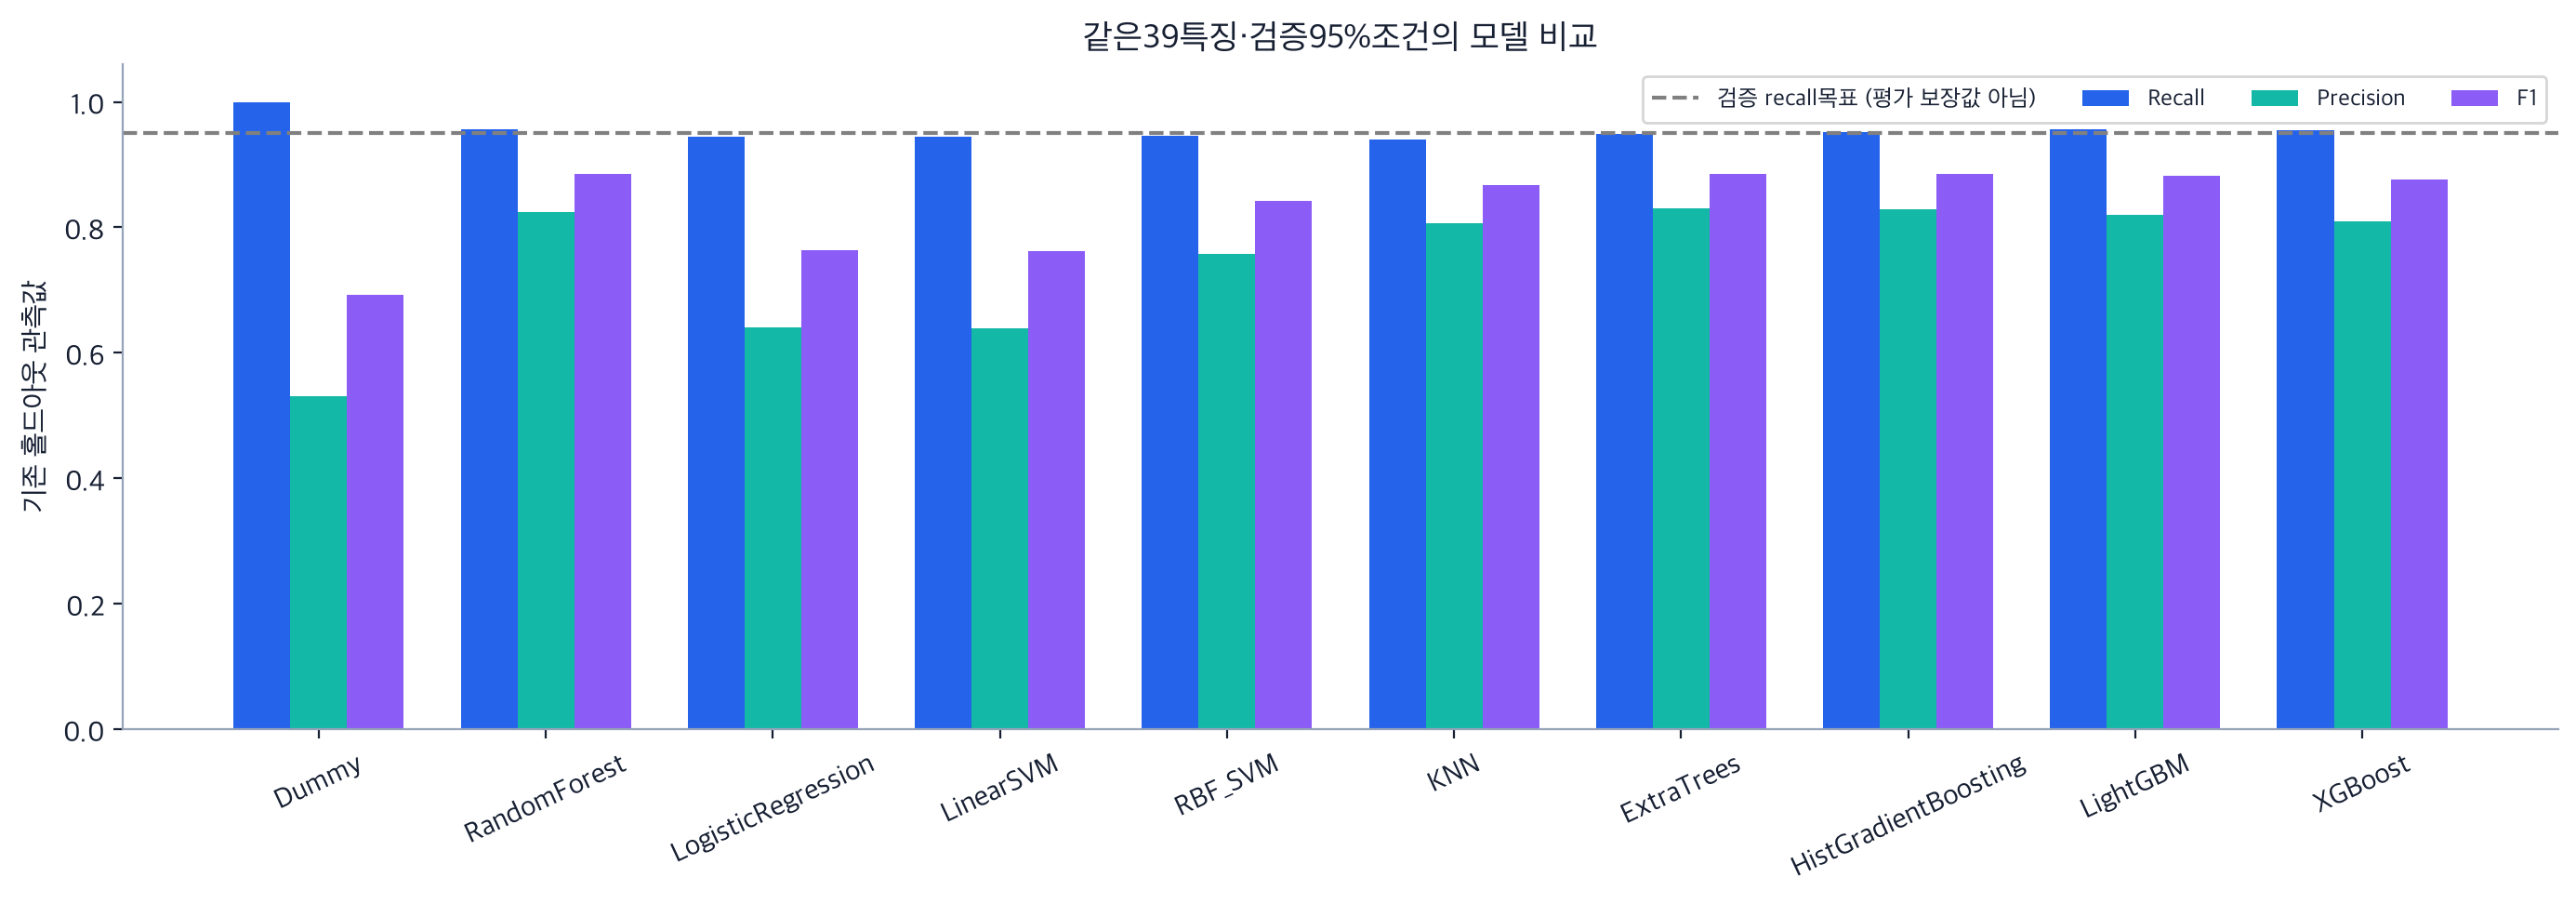

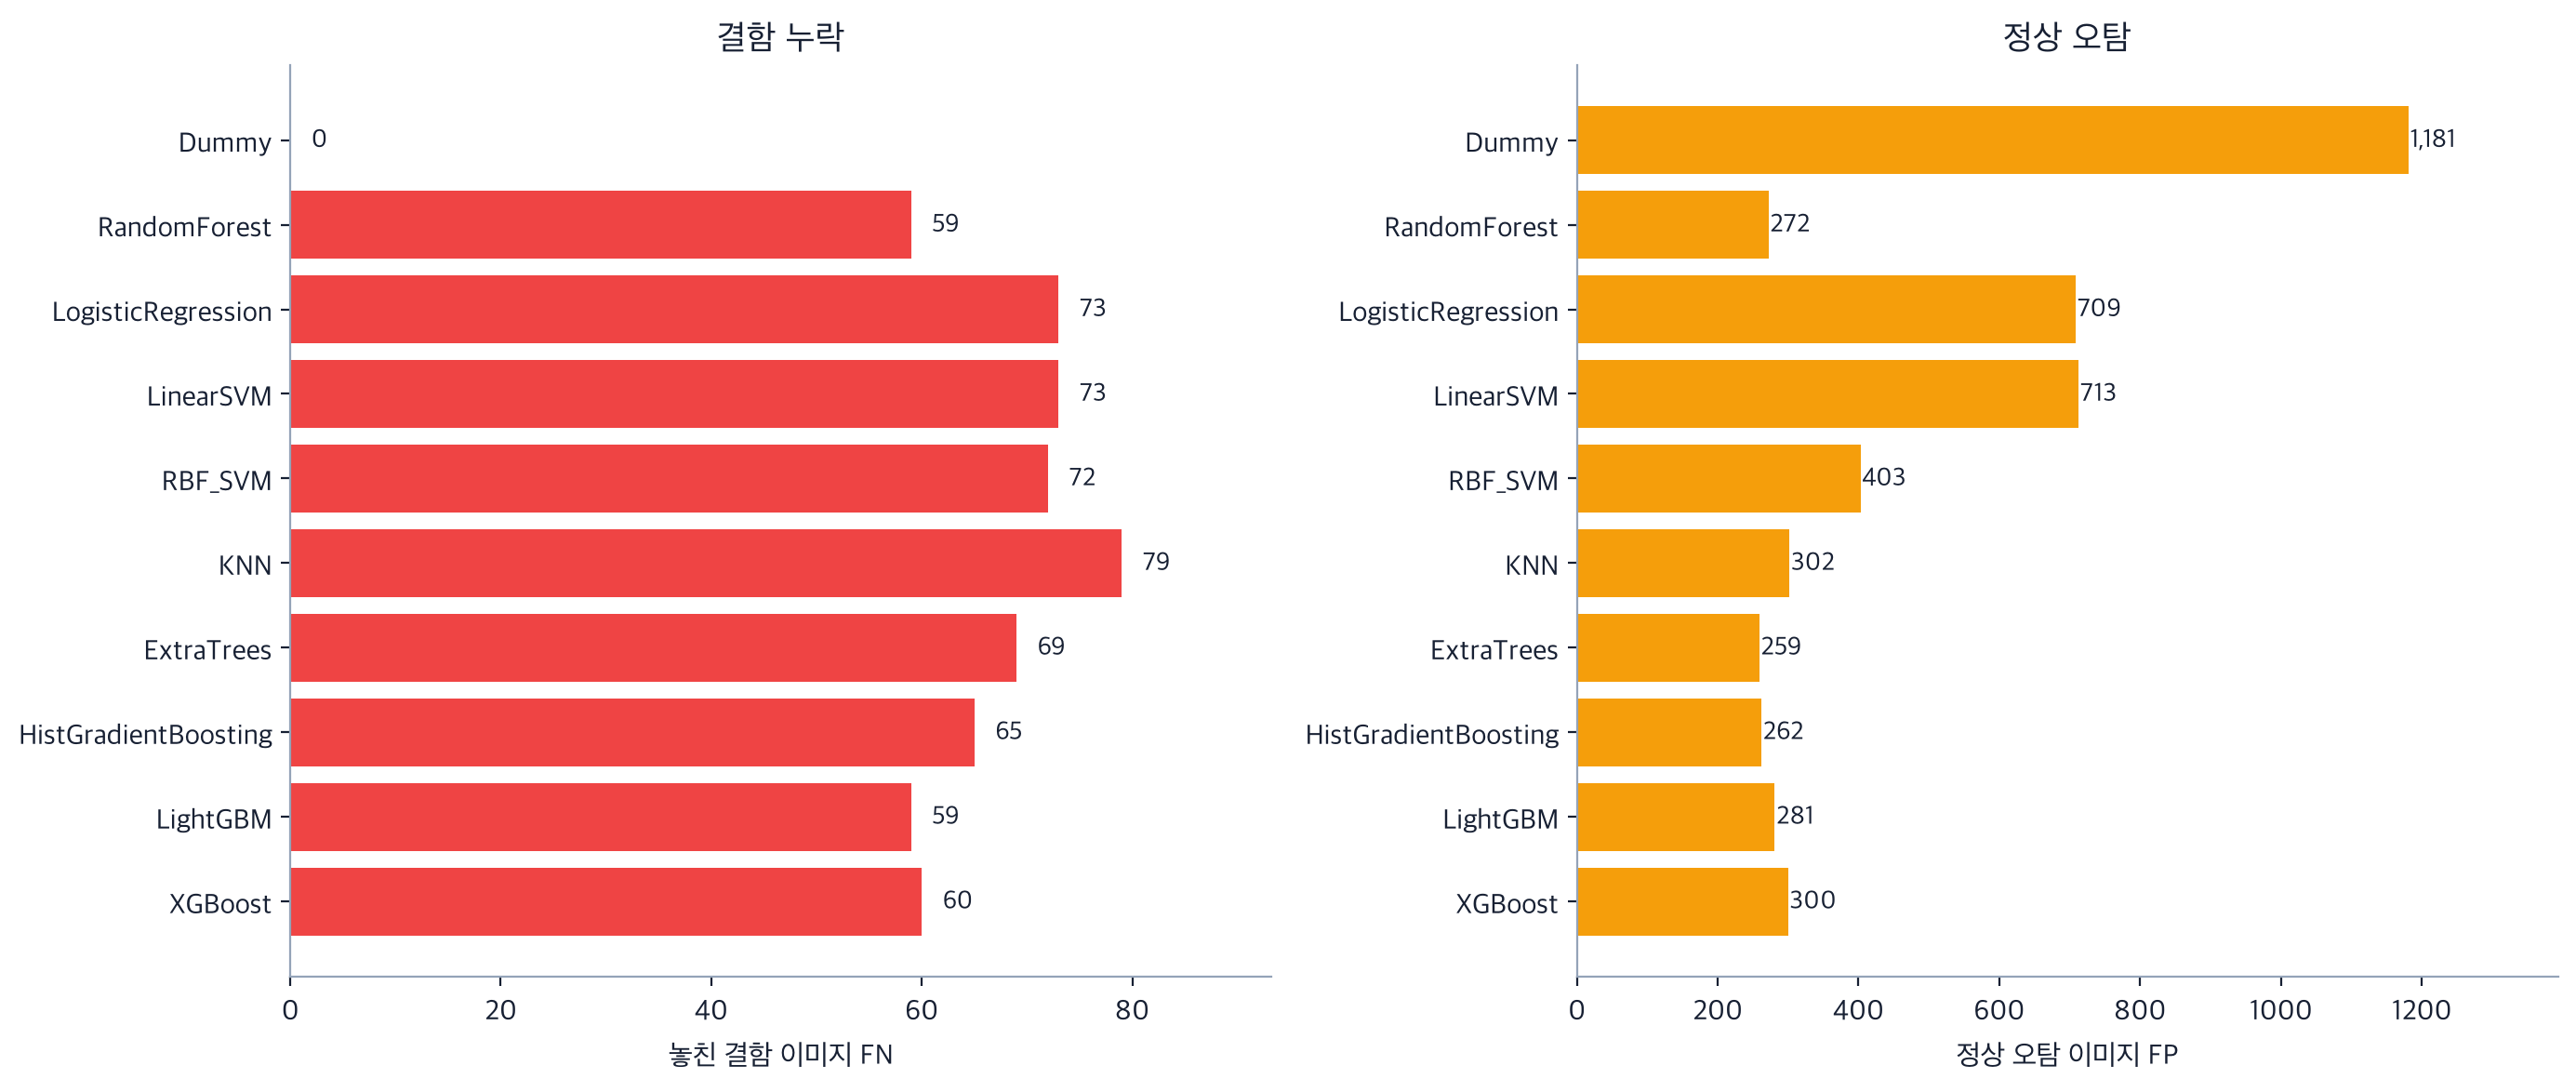

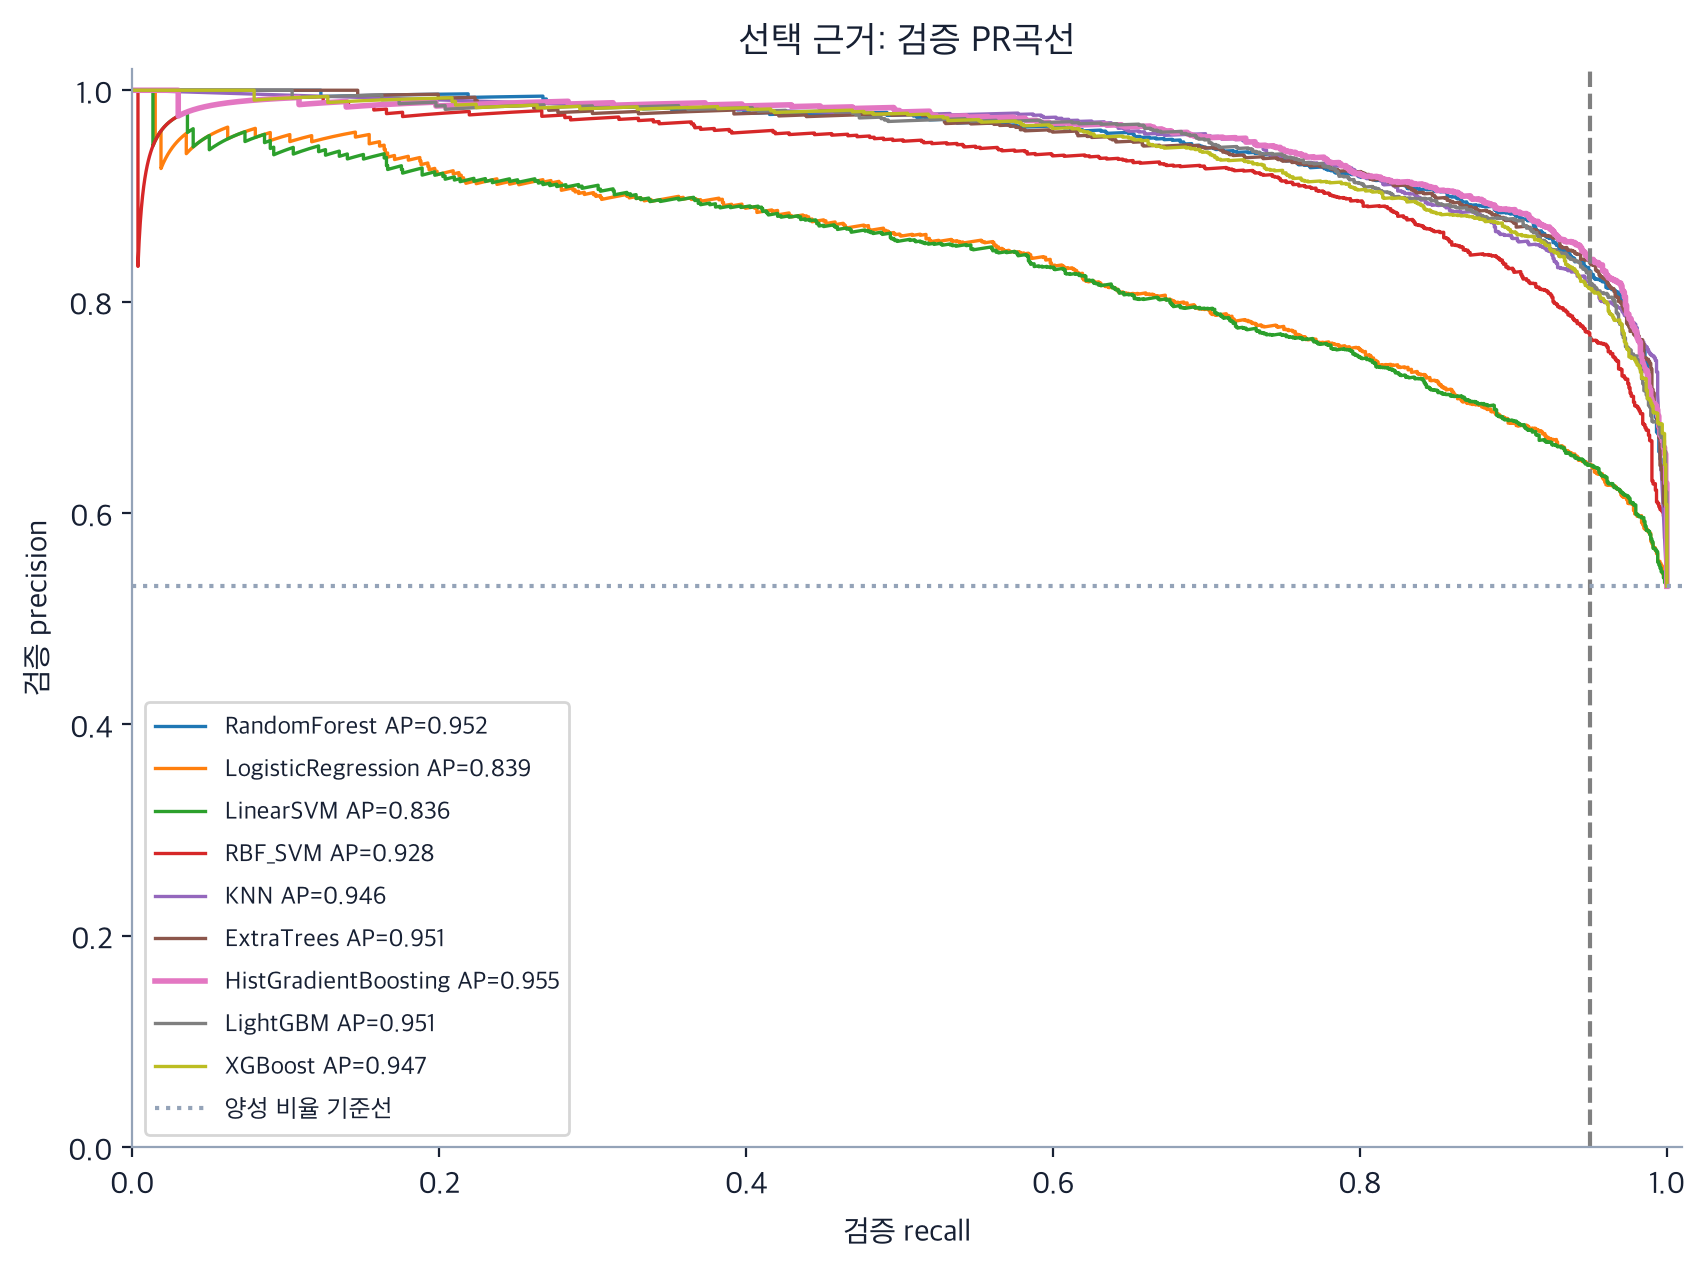

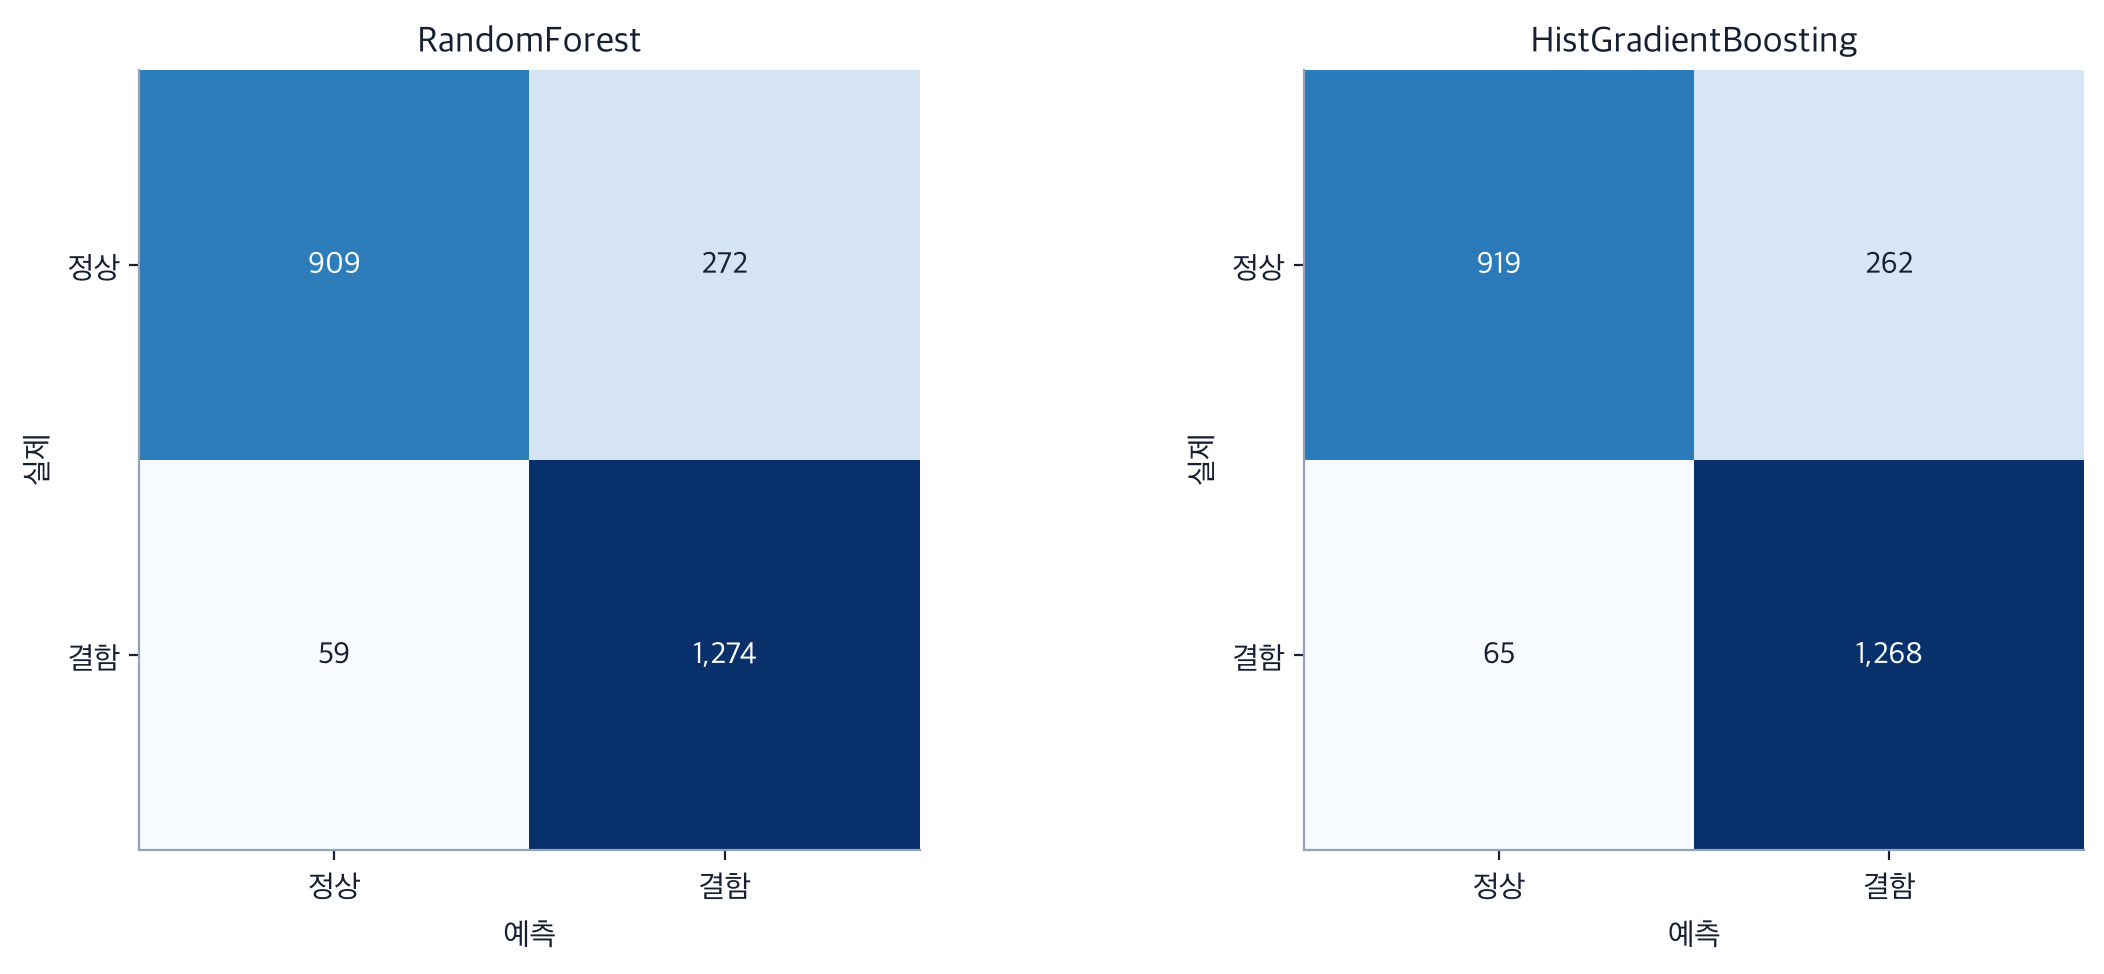

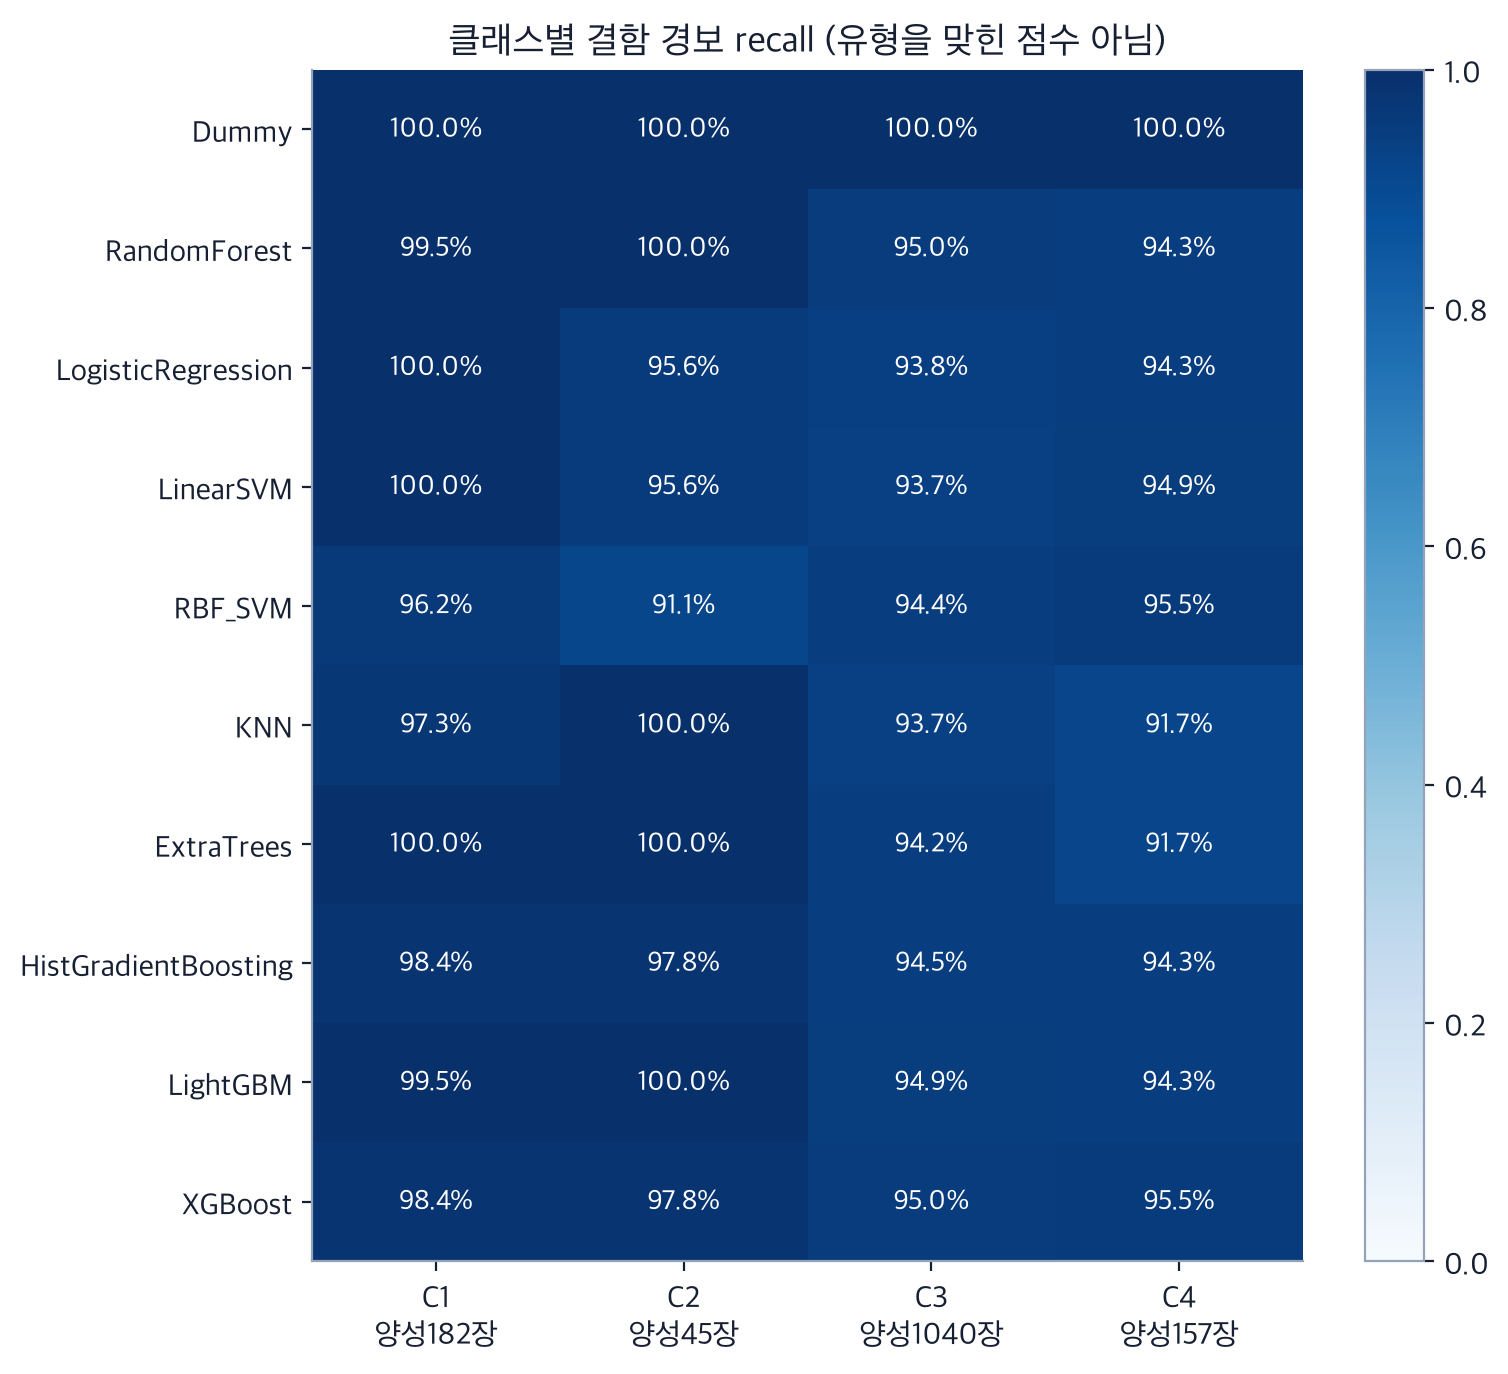

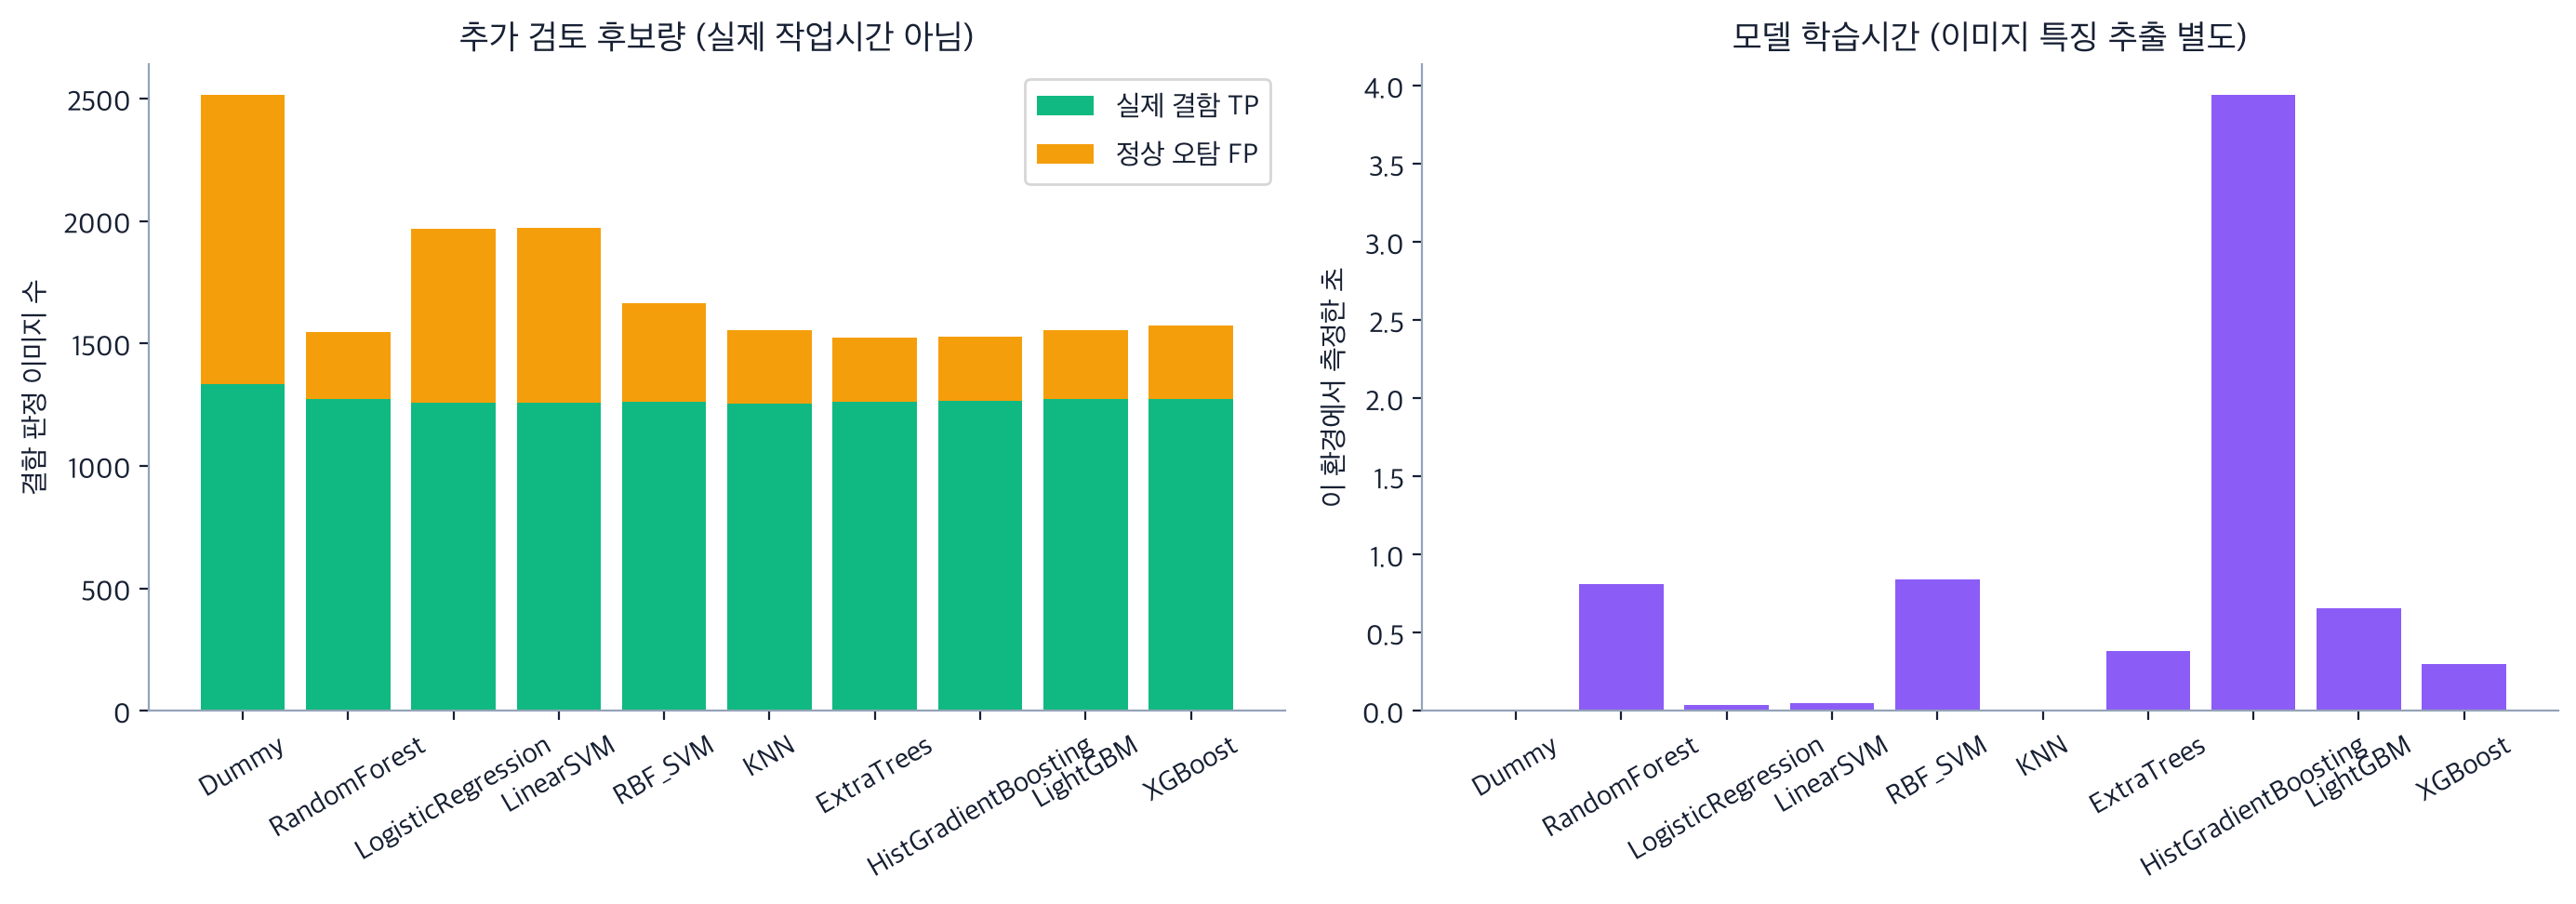

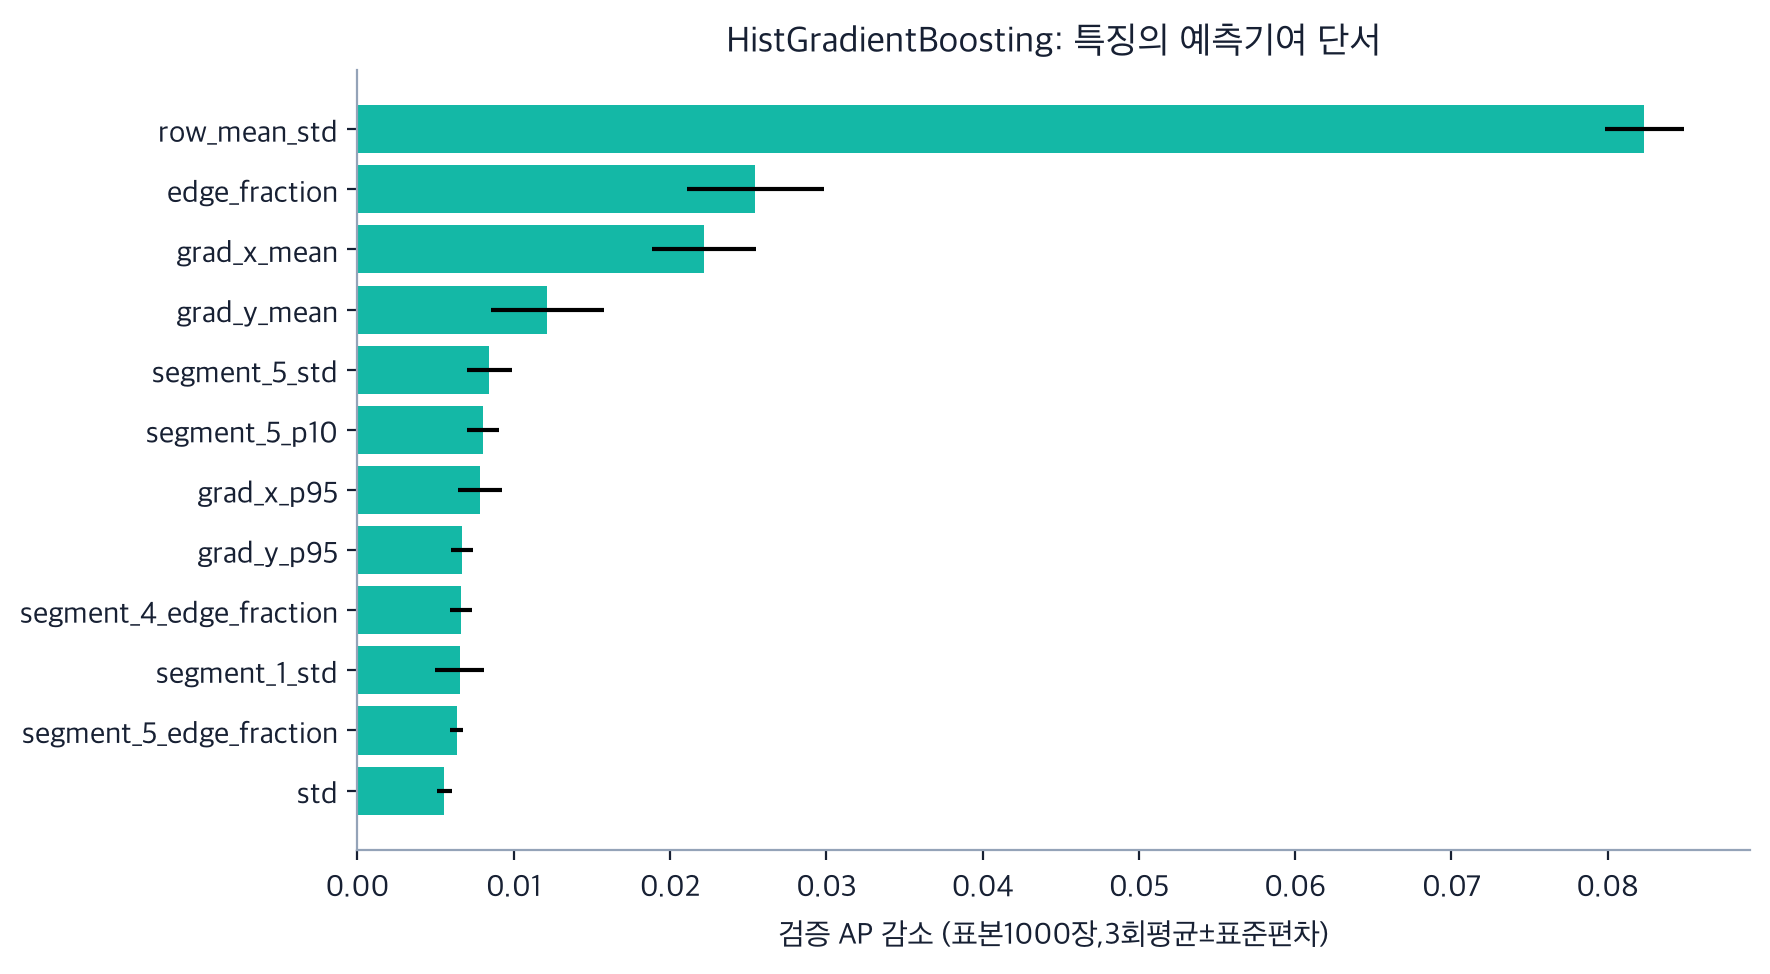

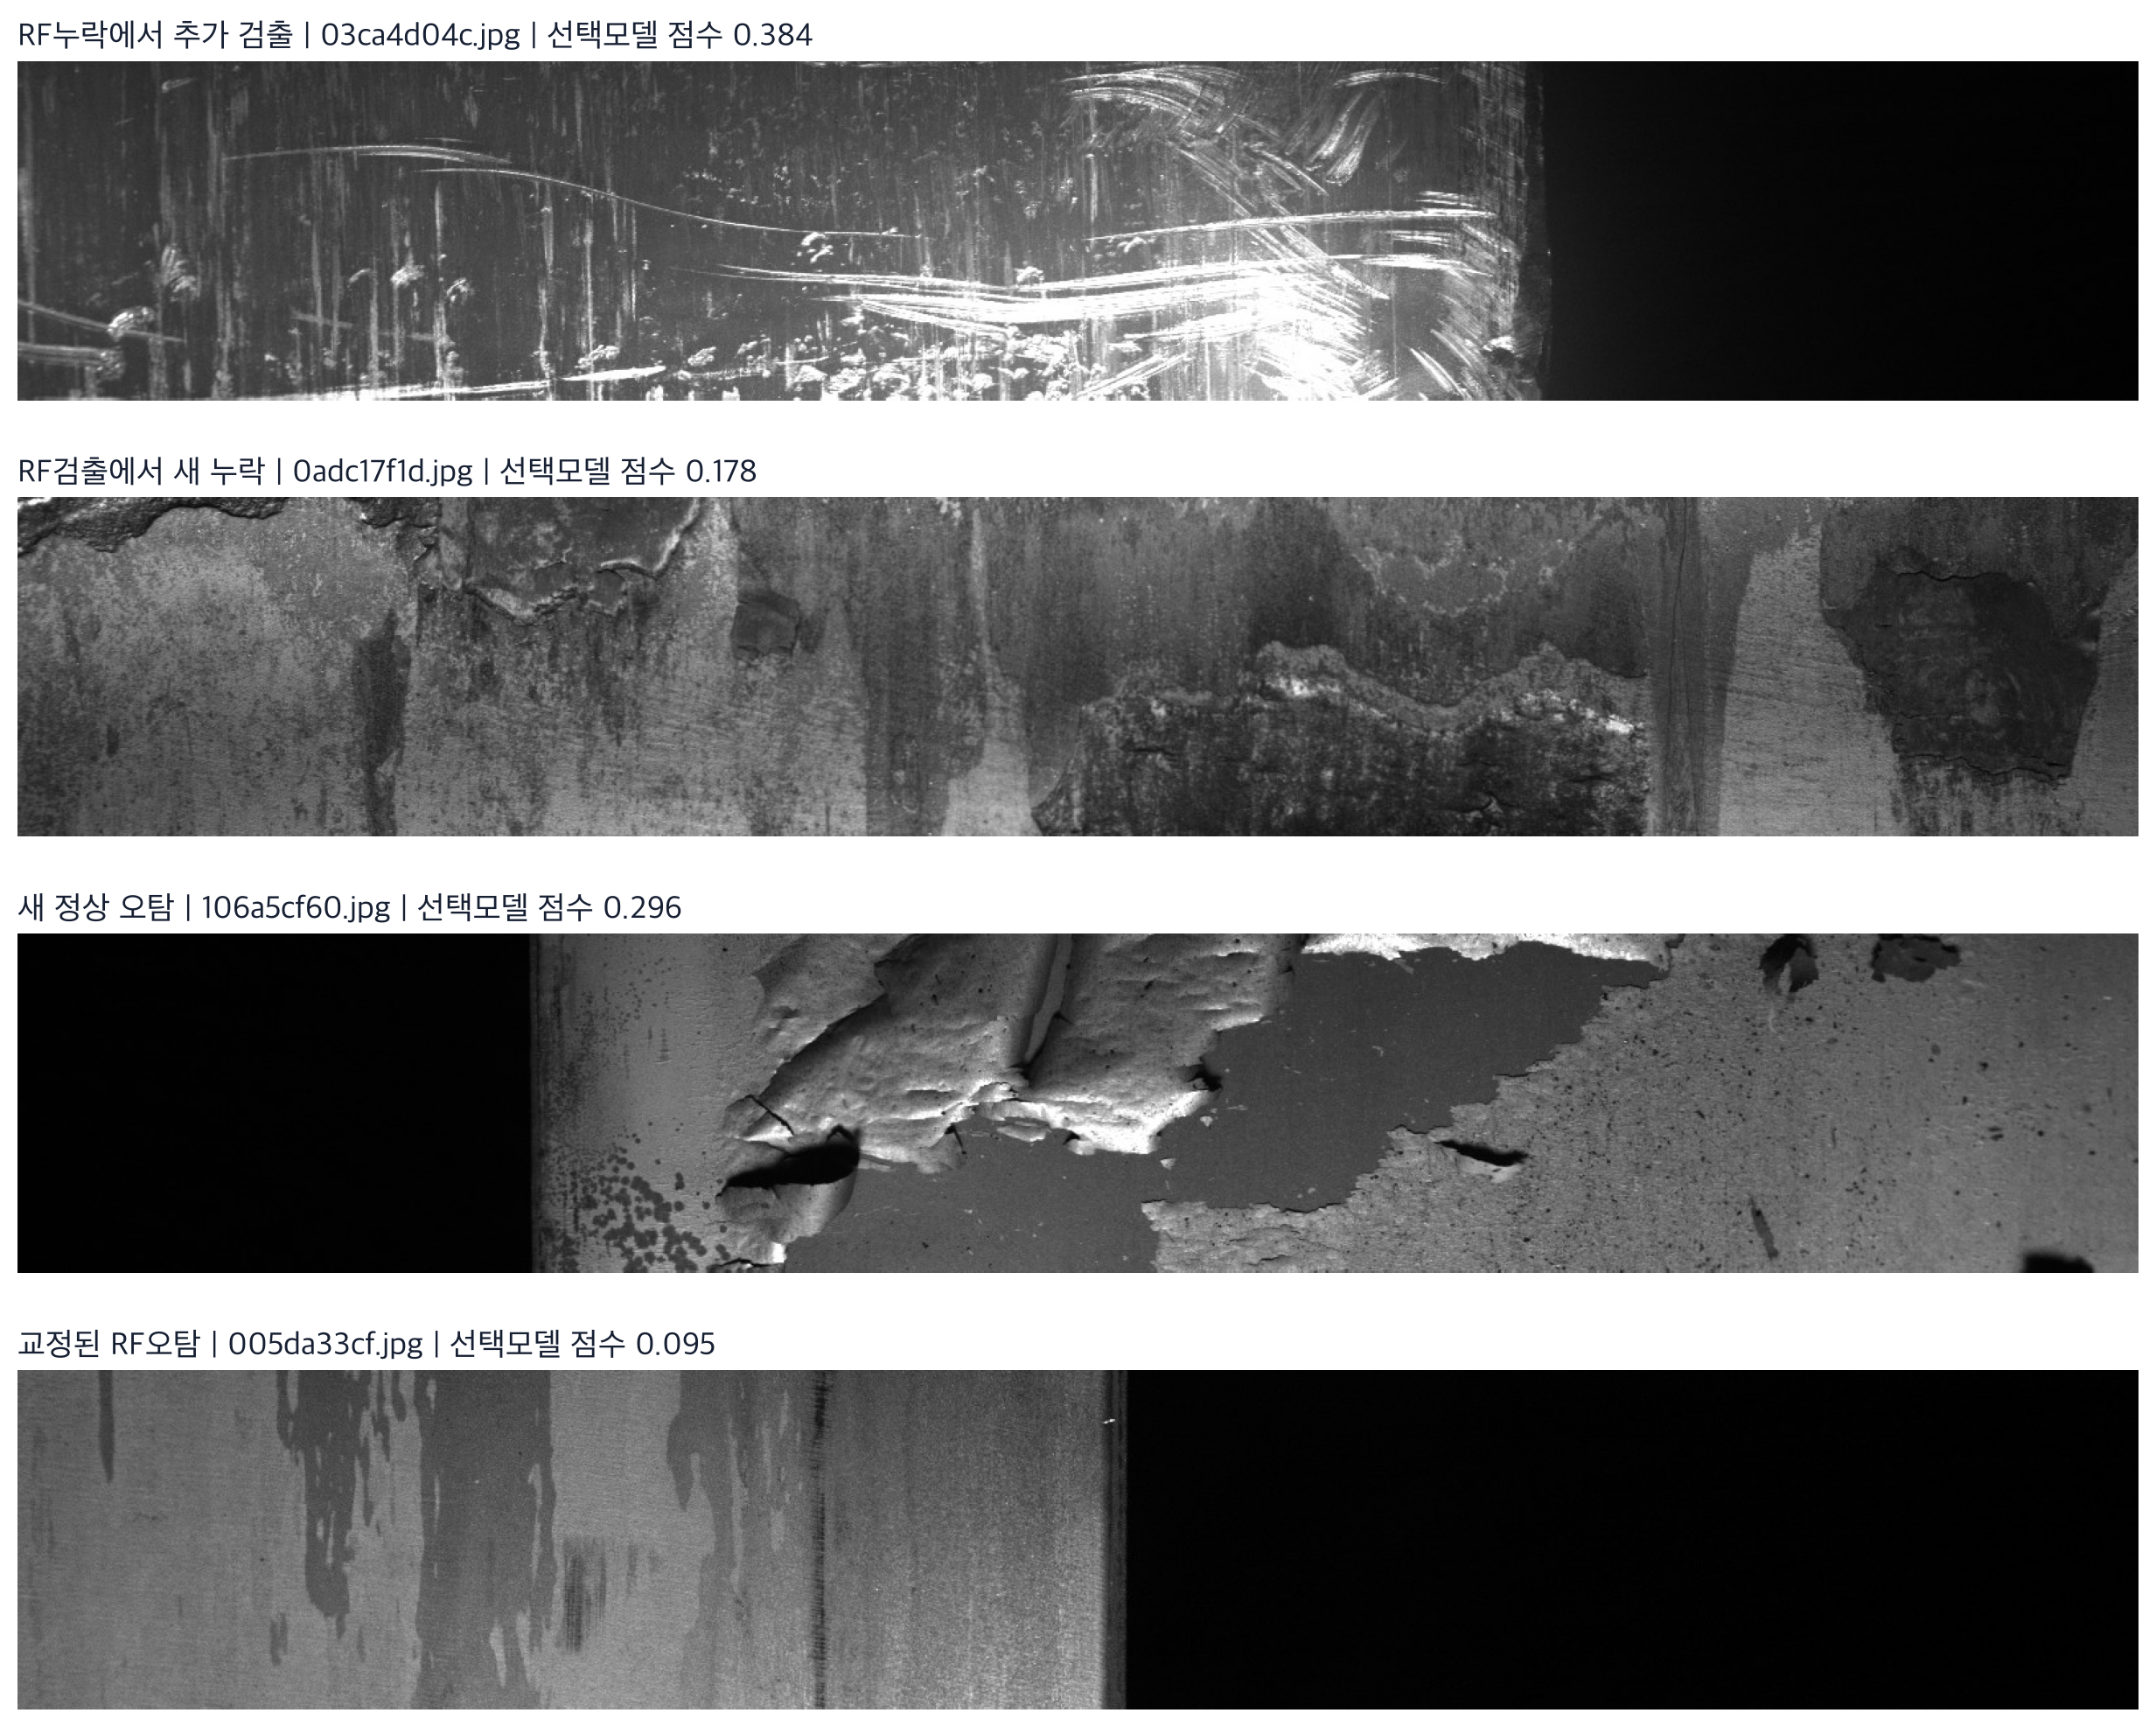

생성한 비교 시각화: 8


In [6]:
figure_count=mc.make_figures(data)
for name in ['01_model_recall_precision_f1','02_false_negatives_positives','03_validation_pr_curves','04_rf_selected_confusion','05_class_alarm_recall','06_review_candidates_training_time','07_selected_feature_importance','08_selected_vs_rf_examples']:
    display(DisplayImage(filename=str(OUT/'figures'/f'{name}.png')))
print('생성한 비교 시각화:',figure_count)

## 6. 정답 없는test_images 예측

앞에서 검증으로 선택한 모델과 임계값을 그대로 적용해5,506장의 정상/결함 점수와 판정CSV를 만듭니다. 정답이 없어 이자료에서 성능을 계산하지 않습니다. 모델은 학습60%에서 학습한 상태를 유지합니다.

이 출력은 이미지유무 판별표입니다. `sample_submission.csv`의마스크/RLE형식을정답으로사용하거나 이진결과를마스크로만들지않습니다.

In [7]:
import test1_ml_report as report
unlabeled_predictions=report.predict_unlabeled(data)
display(unlabeled_predictions.head())
print('정답없는 이미지 예측:',len(unlabeled_predictions))
print('예측 판정 수:',unlabeled_predictions.predicted_defect.value_counts().to_dict())
print('저장:',OUT/'unlabeled_test_predictions.csv')

,ImageId,defect_score,predicted_defect
0,0000f269f.jpg,0.433645,1
1,000ccc2ac.jpg,0.454623,1
2,002451917.jpg,0.615301,1
3,003c5da97.jpg,0.472986,1
4,0042e163f.jpg,0.249587,0


정답없는 이미지 예측: 5506
예측 판정 수: {1: 4309, 0: 1197}
저장: /Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main/model_comparison_outputs/unlabeled_test_predictions.csv


## 7. 결과 요약과 보고서 저장

- 원본RF의TP1274/FN59/FP272/TN909를 정확히 재현했습니다. 비교의 입력·분할이 원본과 일치함을 확인했습니다.
- 검증95%조건으로 선택한 모델은 **HistGradientBoosting**입니다. 평가Recall **95.12%**, Precision **82.88%**, F1 **0.8858**, 누락 **65장**, 정상오탐 **262장**입니다.
- RF의평가Recall **95.57%**, Precision **82.41%**, F1 **0.8850**, 누락 **59장**, 정상오탐 **272장**과 비교하면, 선택모델은 **누락6장 증가·오탐10장 감소**입니다. 모든지표가함께좋아진결과는아닙니다.
- ExtraTrees는Precision82.99%지만Recall94.82%였습니다. 검증목표95%가평가에서도95%를보장하지않습니다.
- 이조건에서는다른모델을돌려도RF보다일관되게낫다고결론내릴만큼차이가크지않습니다. 표준모델설정과한분할의결과로해석합니다.
- 클래스별그림은 ‘해당유형이미지에서결함경보를냈는지’이며4종유형예측의정확도가아닙니다.

보고서와전체모델·선택모델을별도파일로저장합니다.

In [8]:
summary=report.write_report(data)
print(json.dumps(summary,ensure_ascii=False,indent=2))
print('비교 보고서:',OUT/'model_comparison_report.html')
print('평가표:',OUT/'tables/holdout_model_comparison.csv')
print('선택 모델:',OUT/'models/selected_model.joblib')

{
  "trained_models_including_dummy": 10,
  "alternative_models_to_rf": 8,
  "validation_selected_model": "HistGradientBoosting",
  "selected_holdout": {
    "model": "HistGradientBoosting",
    "threshold": 0.2928709808163245,
    "batch_score_ms_per_image": 0.0051170445470377956,
    "recall": 0.9512378094523631,
    "precision": 0.8287581699346406,
    "f1": 0.8857841425078589,
    "accuracy": 0.869928400954654,
    "fpr": 0.2218458933107536,
    "flagged_rate": 0.6085918854415274,
    "tp": 1268,
    "fn": 65,
    "fp": 262,
    "tn": 919,
    "ap": 0.9524505240303031,
    "roc_auc": 0.9523529273512281
  },
  "rf_holdout": {
    "model": "RandomForest",
    "threshold": 0.3814397304986743,
    "batch_score_ms_per_image": 0.014298262912557773,
    "recall": 0.9557389347336834,
    "precision": 0.8240620957309185,
    "f1": 0.8850295241403265,
    "accuracy": 0.8683373110580748,
    "fpr": 0.23031329381879762,
    "flagged_rate": 0.6149562450278441,
    "tp": 1274,
    "fn": 59,
    

In [9]:
# 저장예측으로지표를재계산하고 원본파일·CSV·저장모델의일관성을확인합니다.
verification=report.verify(data)
for filename in ['test1_ml_comparison.py','test1_ml_report.py']:
    compile((PROJECT/filename).read_text(),filename,'exec')
print(json.dumps(verification,ensure_ascii=False,indent=2))
assert verification['original_files_changed']==[]

{
  "original_files_checked": 4,
  "original_files_changed": [],
  "input_csv_unchanged": true,
  "all_models_thresholds_validate_recall95": true,
  "holdout_metrics_recomputed": true,
  "saved_model_score_parity": true,
  "source_feature_parity_checked": true,
  "rf_original_counts_reproduced": true,
  "trained_model_count": 10,
  "new_blind_evaluation": false
}
